In [1]:
from google.colab import drive
drive.mount("/content/drive")

%pip install -q ultralytics pyyaml pandas matplotlib seaborn

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 29.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 7.1 MB/s eta 0:00:00


In [2]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/deeplearning")
DATASET_DIR = PROJECT_DIR / "Dataset" / "Dataset_for_yolo"

MODELS_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"
METRICS_DIR = RESULTS_DIR / "metrics"
PLOTS_DIR = RESULTS_DIR / "plots"
OUTPUTS_DIR = PROJECT_DIR / "outputs"

EVALUATION_DIR = RESULTS_DIR / "yolov8m_evaluation"

for folder in [METRICS_DIR, PLOTS_DIR, OUTPUTS_DIR, EVALUATION_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODELS_DIR / "yolov8m_best.pt"
DATA_YAML = RESULTS_DIR / "data_corrected.yaml"

TEST_IMAGES = DATASET_DIR / "test" / "images"
TEST_LABELS = DATASET_DIR / "test" / "labels"

assert MODEL_PATH.is_file(), (
    f"Trained model not found: {MODEL_PATH}. "
    "Complete Notebook 03 first."
)

assert DATA_YAML.is_file(), (
    f"Corrected data.yaml not found: {DATA_YAML}. "
    "Complete Notebook 03 first."
)

assert TEST_IMAGES.is_dir(), f"Test images not found: {TEST_IMAGES}"
assert TEST_LABELS.is_dir(), f"Test labels not found: {TEST_LABELS}"

print("Model:", MODEL_PATH)
print("Configuration:", DATA_YAML)
print("Test images:", TEST_IMAGES)
print("Evaluation output:", EVALUATION_DIR)

Model: /content/drive/MyDrive/deeplearning/models/yolov8m_best.pt
Configuration: /content/drive/MyDrive/deeplearning/results/data_corrected.yaml
Test images: /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo/test/images
Evaluation output: /content/drive/MyDrive/deeplearning/results/yolov8m_evaluation


In [3]:
import torch
import ultralytics
from ultralytics import YOLO

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    DEVICE = 0
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DEVICE = "cpu"
    print("Using CPU. Evaluation will take longer.")

model = YOLO(str(MODEL_PATH))

print("\nModel task:", model.task)
print("Model classes:", model.names)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics: 8.4.175
PyTorch: 2.11.0+cpu
CUDA available: False
Using CPU. Evaluation will take longer.

Model task: detect
Model classes: {0: 'bottle'}


In [4]:
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

test_images = sorted(
    p for p in TEST_IMAGES.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)

test_labels = sorted(TEST_LABELS.rglob("*.txt"))

print("Test images:", len(test_images))
print("Test label files:", len(test_labels))

if not test_images:
    raise ValueError("No test images found.")

if not test_labels:
    raise ValueError("No test labels found.")

Test images: 200
Test label files: 200


In [5]:
test_metrics = model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=640,
    batch=8,
    device=DEVICE,
    workers=2,
    plots=True,
    save_json=True,
    project=str(EVALUATION_DIR),
    name="test_metrics",
    exist_ok=True,
    verbose=True
)

print("Test evaluation completed.")

Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 92 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 2.8±4.1 ms, read: 9.5±20.9 MB/s, size: 109.3 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo/test/labels... 200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 2.4it/s 1:22
val: New cache created: /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 13.4s/it 5:35
                   all        200        498      0.898      0.844      0.897      0.464
Speed: 4.2ms preprocess, 1653.4ms inference, 0.0ms loss, 1.8ms postprocess per image
Saving /content/drive/MyD

In [6]:
import pandas as pd
import numpy as np

box_metrics = test_metrics.box

evaluation_results = {
    "model": "YOLOv8m",
    "dataset": "Plastic bottle test set",
    "test_images": len(test_images),
    "precision": float(np.asarray(box_metrics.p).mean()),
    "recall": float(np.asarray(box_metrics.r).mean()),
    "mAP50": float(box_metrics.map50),
    "mAP50_95": float(box_metrics.map),
}

evaluation_df = pd.DataFrame(
    list(evaluation_results.items()),
    columns=["Metric", "Value"]
)

display(evaluation_df)

evaluation_csv = METRICS_DIR / "yolov8m_test_metrics.csv"
evaluation_df.to_csv(evaluation_csv, index=False)

print("Metrics saved to:", evaluation_csv)

,Metric,Value
0,model,YOLOv8m
1,dataset,Plastic bottle test set
2,test_images,200
3,precision,0.897558
4,recall,0.844491
5,mAP50,0.896926
6,mAP50_95,0.463955


Metrics saved to: /content/drive/MyDrive/deeplearning/results/metrics/yolov8m_test_metrics.csv


In [7]:
EVAL_RUN_DIR = EVALUATION_DIR / "test_metrics"

print("Evaluation directory:", EVAL_RUN_DIR)

if EVAL_RUN_DIR.exists():
    for path in sorted(EVAL_RUN_DIR.iterdir()):
        print(path.name)
else:
    print("Evaluation directory not found. Check the path printed by Cell 5.")

Evaluation directory: /content/drive/MyDrive/deeplearning/results/yolov8m_evaluation/test_metrics
BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
confusion_matrix.png
confusion_matrix_normalized.png
predictions.json
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg


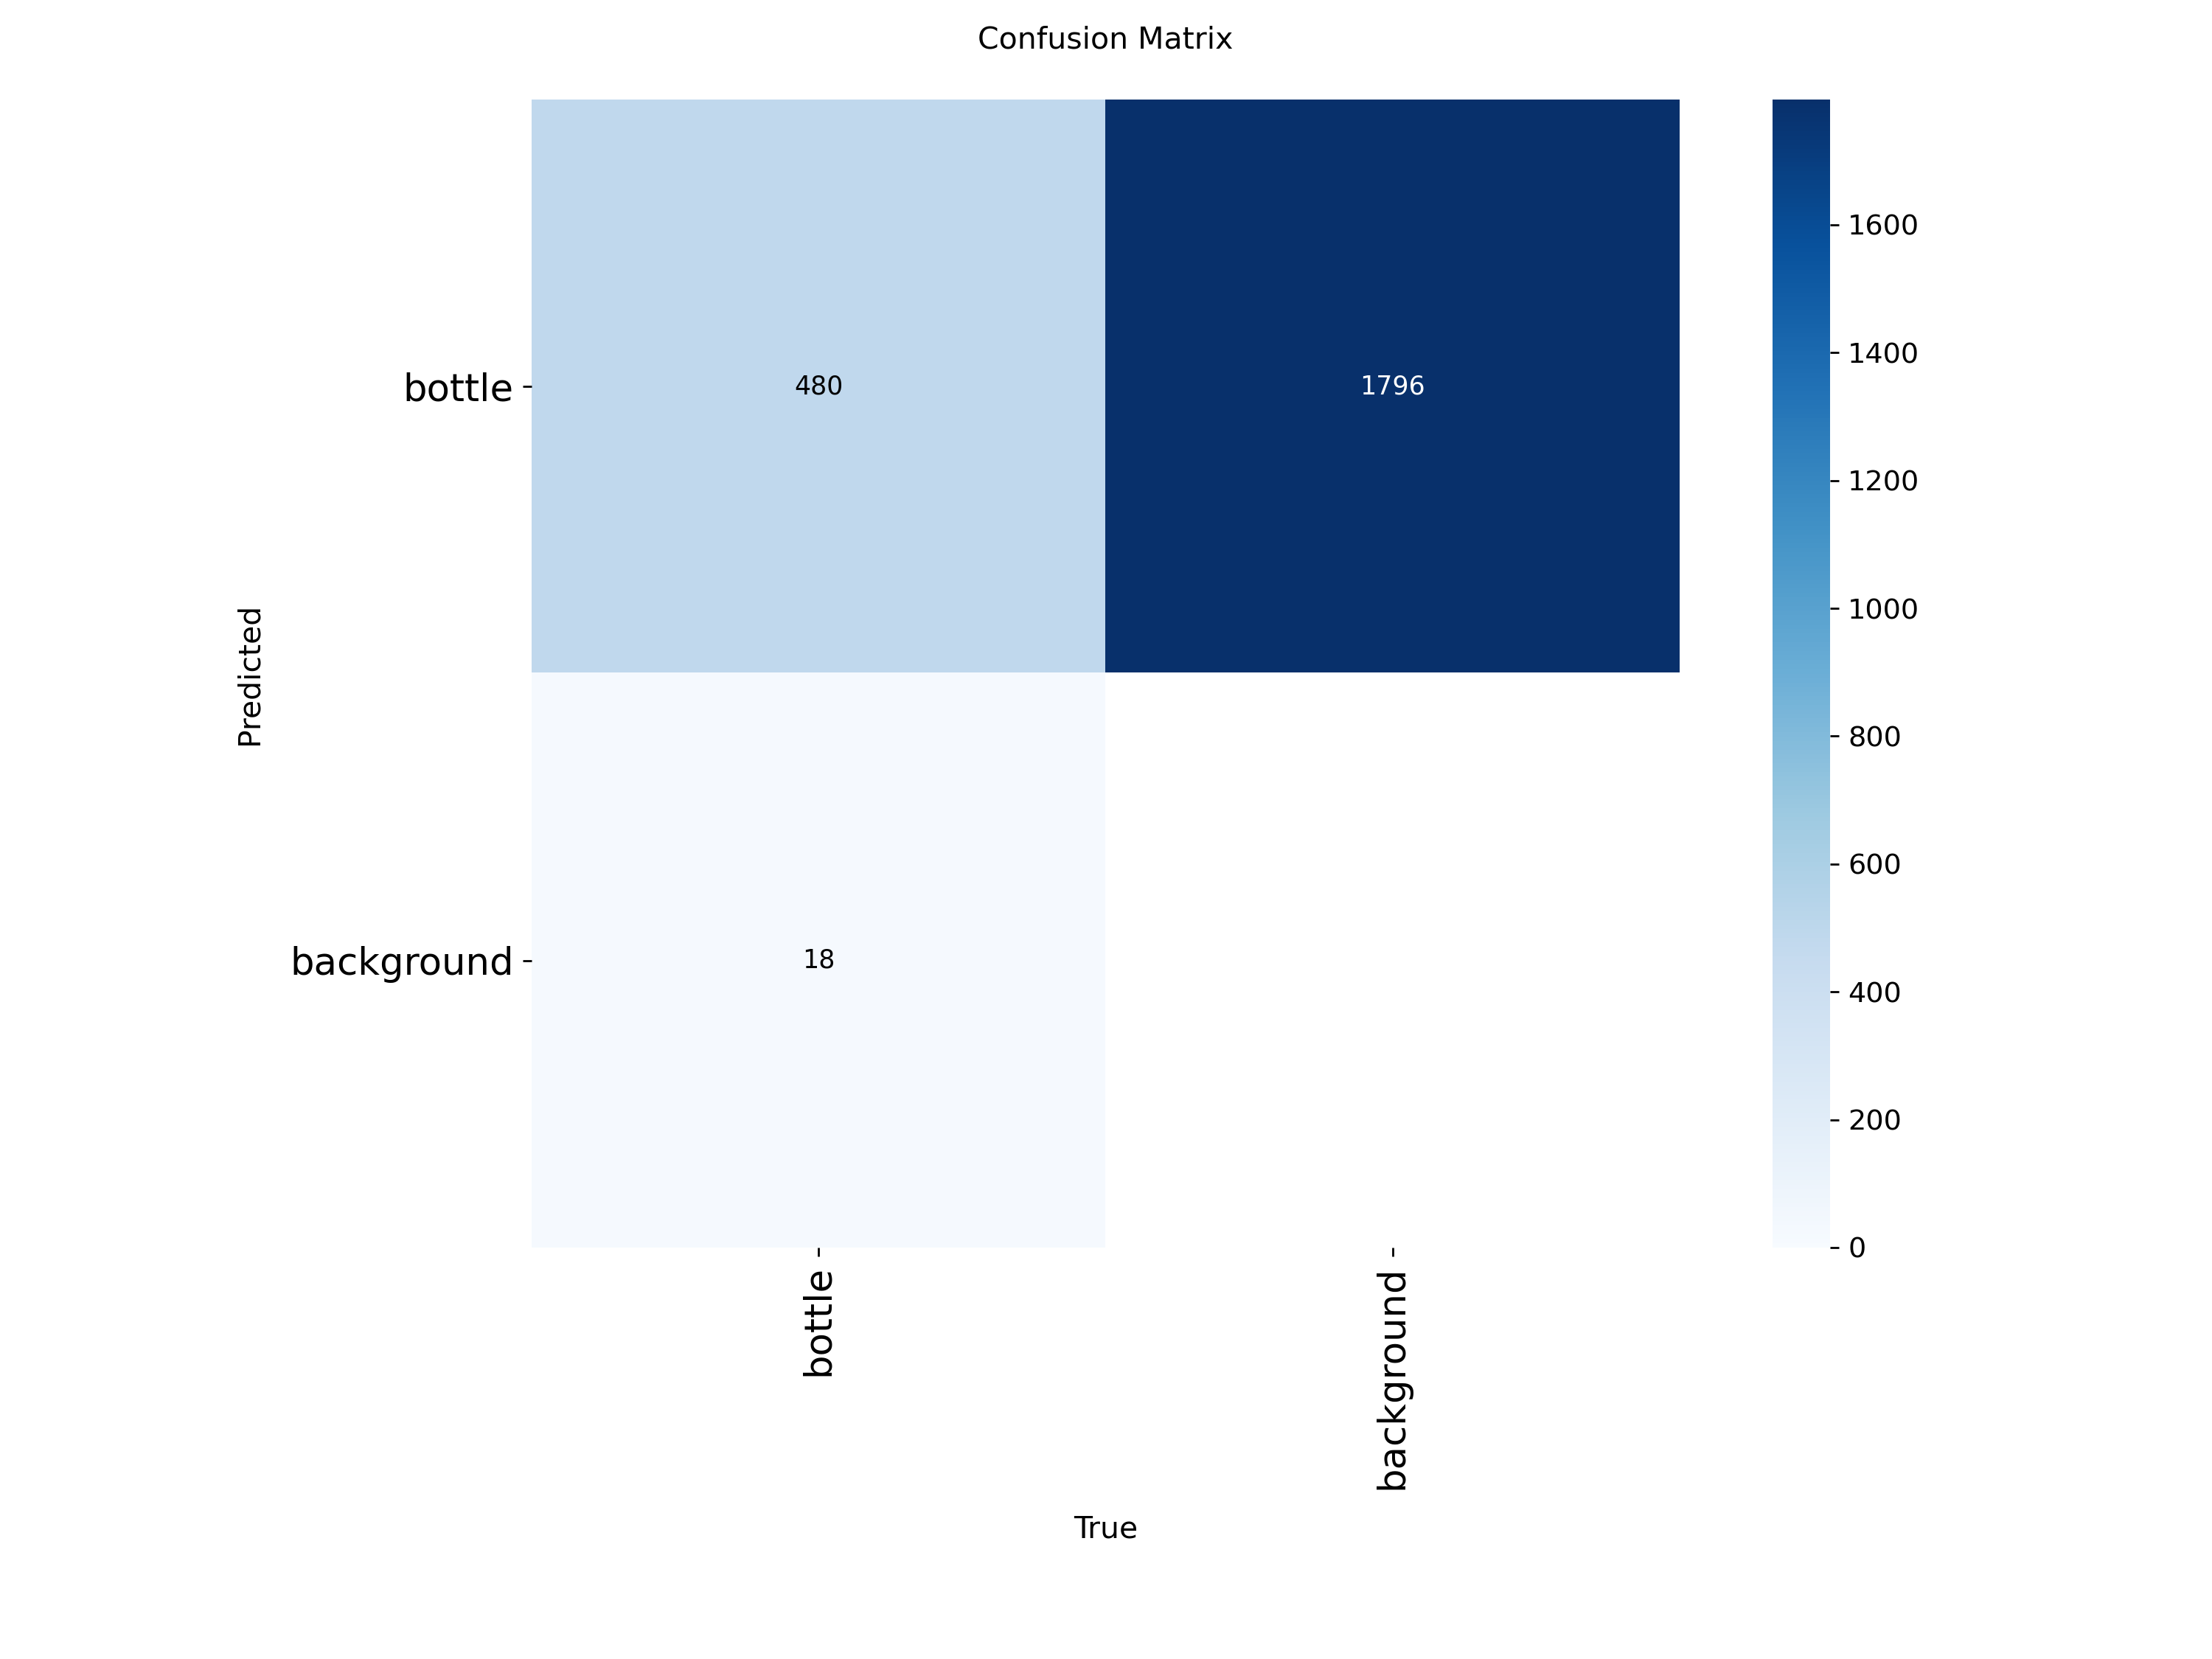

In [8]:
from IPython.display import display, Image as IPyImage

confusion_path = EVAL_RUN_DIR / "confusion_matrix.png"

if confusion_path.exists():
    display(IPyImage(filename=str(confusion_path)))
else:
    print("Confusion matrix image was not found.")

In [9]:
prediction_results = model.predict(
    source=str(TEST_IMAGES),
    imgsz=640,
    conf=0.25,
    iou=0.7,
    device=DEVICE,
    batch=8,
    save=True,
    save_conf=True,
    project=str(OUTPUTS_DIR),
    name="yolov8m_test_predictions",
    exist_ok=True,
    verbose=True
)

PREDICTION_DIR = OUTPUTS_DIR / "yolov8m_test_predictions"

print("Predictions saved to:", PREDICTION_DIR)


image 1/200 /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo/test/images/000001_jpg.rf.3f7ad8a726437bc9a87073dc1cc0a290.jpg: 640x640 8 bottles, 1425.7ms
image 2/200 /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo/test/images/000002_jpg.rf.6196d69fa7cd41a627afb27d98f85980.jpg: 640x640 1 bottle, 1425.7ms
image 3/200 /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo/test/images/000003_jpg.rf.bc53072becbaf9f9aaa6315d9351e6fa.jpg: 640x640 1 bottle, 1425.7ms
image 4/200 /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo/test/images/000004_jpg.rf.29db354b0426301ed33e2f28b73989cd.jpg: 640x640 10 bottles, 1425.7ms
image 5/200 /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo/test/images/000005_jpg.rf.bf0d80d289cfd165f8b1e292c1268be6.jpg: 640x640 2 bottles, 1425.7ms
image 6/200 /content/drive/MyDrive/deeplearning/Dataset/Dataset_for_yolo/test/images/000006_jpg.rf.61e8560f438fd983f4e1cfda61bd7f2d.jpg: 640x640 4 bottles, 1425.7ms
image 7/20

In [10]:
import random
import matplotlib.pyplot as plt
from PIL import Image

saved_images = sorted(
    p for p in PREDICTION_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)

if not saved_images:
    print("No annotated prediction images found.")
else:
    samples = random.Random(42).sample(
        saved_images, min(6, len(saved_images))
    )

    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    axes = axes.flatten()

    for ax in axes:
        ax.axis("off")

    for ax, image_path in zip(axes, samples):
        with Image.open(image_path) as im:
            ax.imshow(im.convert("RGB"))

        ax.set_title(image_path.name, fontsize=8)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [11]:
import json
from datetime import datetime

report = {
    "project": "Plastic Waste Detection and Segmentation",
    "detector": "YOLOv8m",
    "class_names": model.names,
    "test_image_count": len(test_images),
    "metrics": {
        "precision": evaluation_results["precision"],
        "recall": evaluation_results["recall"],
        "mAP50": evaluation_results["mAP50"],
        "mAP50_95": evaluation_results["mAP50_95"],
    },
    "model_path": str(MODEL_PATH),
    "evaluation_time": datetime.now().isoformat(timespec="seconds"),
}

REPORT_PATH = METRICS_DIR / "yolov8m_test_report.json"

with open(REPORT_PATH, "w") as f:
    json.dump(report, f, indent=4)

print(json.dumps(report, indent=4))
print("\nReport saved to:", REPORT_PATH)

{
    "project": "Plastic Waste Detection and Segmentation",
    "detector": "YOLOv8m",
    "class_names": {
        "0": "bottle"
    },
    "test_image_count": 200,
    "metrics": {
        "precision": 0.8975575972814012,
        "recall": 0.8444909698163192,
        "mAP50": 0.8969258825381787,
        "mAP50_95": 0.4639548608207281
    },
    "model_path": "/content/drive/MyDrive/deeplearning/models/yolov8m_best.pt",
    "evaluation_time": "2026-10-11T17:40:59"
}

Report saved to: /content/drive/MyDrive/deeplearning/results/metrics/yolov8m_test_report.json
